<a href="https://colab.research.google.com/github/44yushid0nde/MLOpsLab/blob/main/MLOps_EXP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORT REQUIRED LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

print("All libraries imported successfully.")

All libraries imported successfully.


LOAD THE DATASET

In [2]:
wine = load_wine(as_frame=True)

X = wine.data
y = wine.target

df = X.copy()
df["target"] = y

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Number of classes:", len(wine.target_names))

print("\nFirst five rows:")
display(df.head())

print("\nClass names:")
print(wine.target_names)


Dataset loaded successfully!
Dataset shape: (178, 14)
Number of samples: 178
Number of features: 13
Number of classes: 3

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Class names:
['class_0' 'class_1' 'class_2']


EXPLORE AND UNDERSTAND THE DATASET

In [5]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

In [6]:
print("\nStatistical summary:")
display(X.describe().round(2))


Statistical summary:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


In [7]:
print("\nMissing values in each column:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())


Missing values in each column:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total missing values: 0


In [8]:
print("\nClass distribution:")
print(y.value_counts().sort_index().rename(
    index={i: name for i, name in enumerate(wine.target_names)}
))


Class distribution:
target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


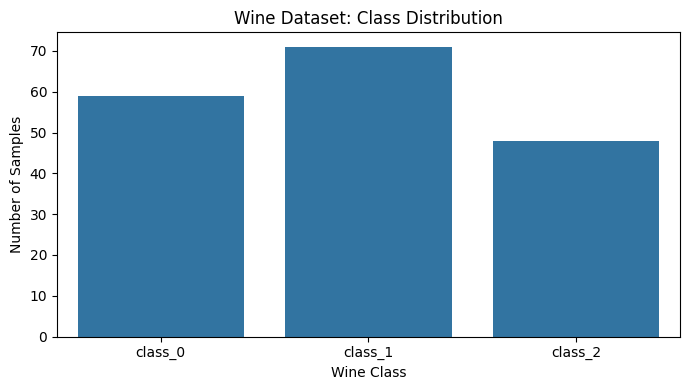

In [9]:
# Visualize class distribution
plt.figure(figsize=(7, 4))
sns.countplot(x=y.map(
    {i: name for i, name in enumerate(wine.target_names)}
))
plt.title("Wine Dataset: Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

VISUALIZE FEATURE CORRELATIONS

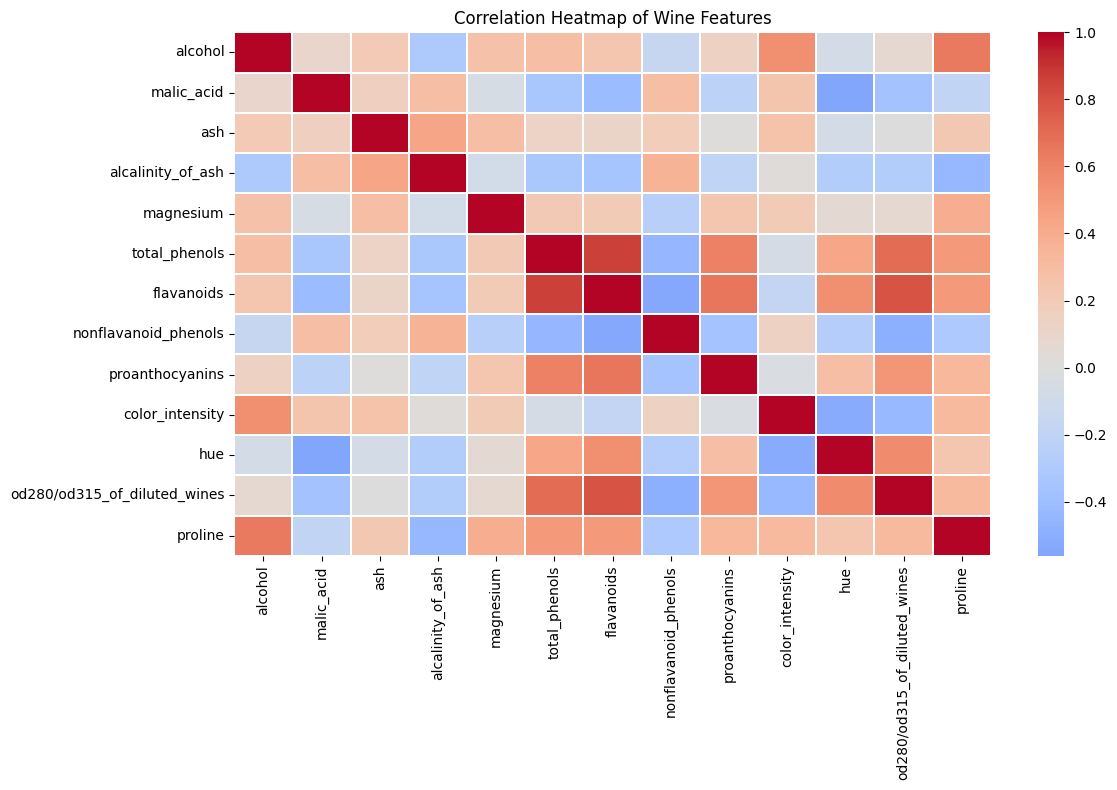

In [10]:
plt.figure(figsize=(12, 8))

correlation_matrix = X.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Correlation Heatmap of Wine Features")
plt.tight_layout()
plt.show()

SPLIT THE DATA INTO TRAINING AND TESTING SETS

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nData split completed successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Data split completed successfully!
Training samples: 142
Testing samples: 36


CREATE THE LOGISTIC REGRESSION PIPELINE

In [12]:
# Pipeline stages:
# 1. Impute missing values if any exist
# 2. Standardize numerical features
# 3. Train Logistic Regression classifier

logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=3000))
])

print("\nLogistic Regression pipeline:")
print(logistic_pipeline)


Logistic Regression pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=3000))])


TRAIN THE LOGISTIC REGRESSION MODEL

In [13]:
logistic_pipeline.fit(X_train, y_train)

print("\nLogistic Regression model trained successfully.")


Logistic Regression model trained successfully.


MAKE PREDICTIONS

In [14]:
y_pred = logistic_pipeline.predict(X_test)
y_prob = logistic_pipeline.predict_proba(X_test)

print("\nActual class labels:")
print(y_test.to_numpy())

print("\nPredicted class labels:")
print(y_pred)


Actual class labels:
[0 2 0 1 1 0 0 1 1 2 1 2 0 2 0 1 1 0 1 0 1 1 0 0 1 1 0 2 1 2 0 2 1 2 2 2]

Predicted class labels:
[0 1 0 1 1 0 0 1 1 2 1 2 0 2 0 1 1 0 1 0 1 1 0 0 1 1 0 2 1 2 0 2 1 2 2 2]


EVALUATE THE LOGISTIC REGRESSION MODEL

In [15]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

roc_auc = roc_auc_score(
    y_test, y_prob, multi_class="ovr", average="weighted"
)

print("\n------------------------------")
print("LOGISTIC REGRESSION - EVALUATION")
print("--------------------------------")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(wine.target_names)),
    target_names=wine.target_names,
    zero_division=0
))


------------------------------
LOGISTIC REGRESSION - EVALUATION
--------------------------------
Accuracy  : 0.9722
Precision : 0.9741
Recall    : 0.9722
F1 Score  : 0.9720
ROC-AUC   : 1.0000

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



PLOT THE CONFUSION MATRIX

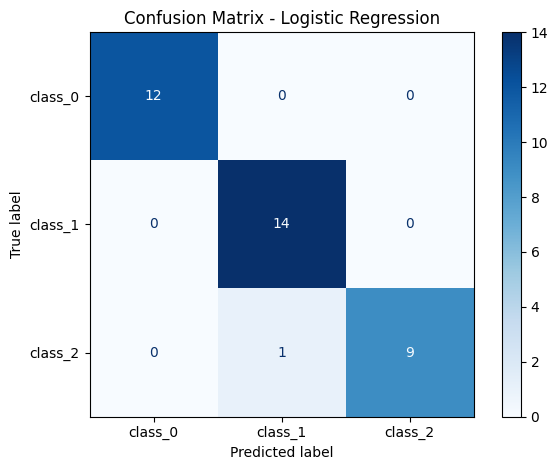

In [16]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(wine.target_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=wine.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

CROSS-VALIDATION

In [17]:
cv_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("\n---------------------")
print("5-FOLD CROSS-VALIDATION")
print("-----------------------")

print("Individual fold scores:", np.round(cv_scores, 4))
print(f"Mean CV accuracy: {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")


---------------------
5-FOLD CROSS-VALIDATION
-----------------------
Individual fold scores: [1.     0.9655 1.     1.     1.    ]
Mean CV accuracy: 0.9931
Standard deviation: 0.0138


CREATE A RANDOM FOREST PIPELINE

In [18]:
# Random Forest does not require feature scaling.
# The imputer keeps the preprocessing pipeline robust.

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_pipeline.fit(X_train, y_train)

print("\nRandom Forest model trained successfully.")


Random Forest model trained successfully.


EVALUATE RANDOM FOREST

In [19]:
rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

rf_precision = precision_score(
    y_test, rf_pred, average="weighted", zero_division=0
)

rf_recall = recall_score(
    y_test, rf_pred, average="weighted", zero_division=0
)

rf_f1 = f1_score(
    y_test, rf_pred, average="weighted", zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_test, rf_prob, multi_class="ovr", average="weighted"
)

print("\n------------------------")
print("RANDOM FOREST - EVALUATION")
print("\n------------------------")

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1 Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    labels=np.arange(len(wine.target_names)),
    target_names=wine.target_names,
    zero_division=0
))


------------------------
RANDOM FOREST - EVALUATION

------------------------
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000
ROC-AUC   : 1.0000

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



RANDOM FOREST CONFUSION MATRIX

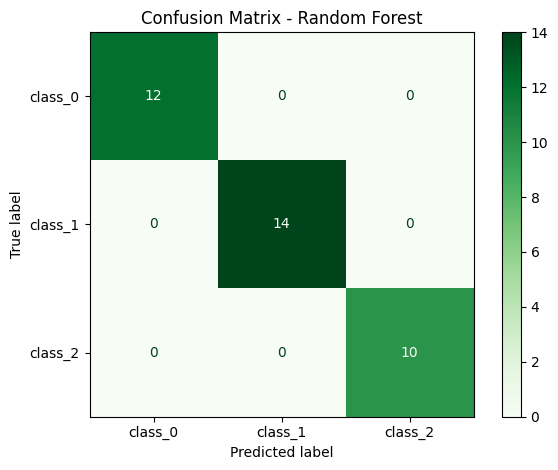

In [20]:
rf_cm = confusion_matrix(
    y_test,
    rf_pred,
    labels=np.arange(len(wine.target_names))
)

ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=wine.target_names
).plot(cmap="Greens", values_format="d")

plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

COMPARE BOTH MODELS


--------------------------
MODEL PERFORMANCE COMPARISON

--------------------------


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9722,0.9741,0.9722,0.972,1.0
1,Random Forest,1.0000,1.0000,1.0000,1.000,1.0


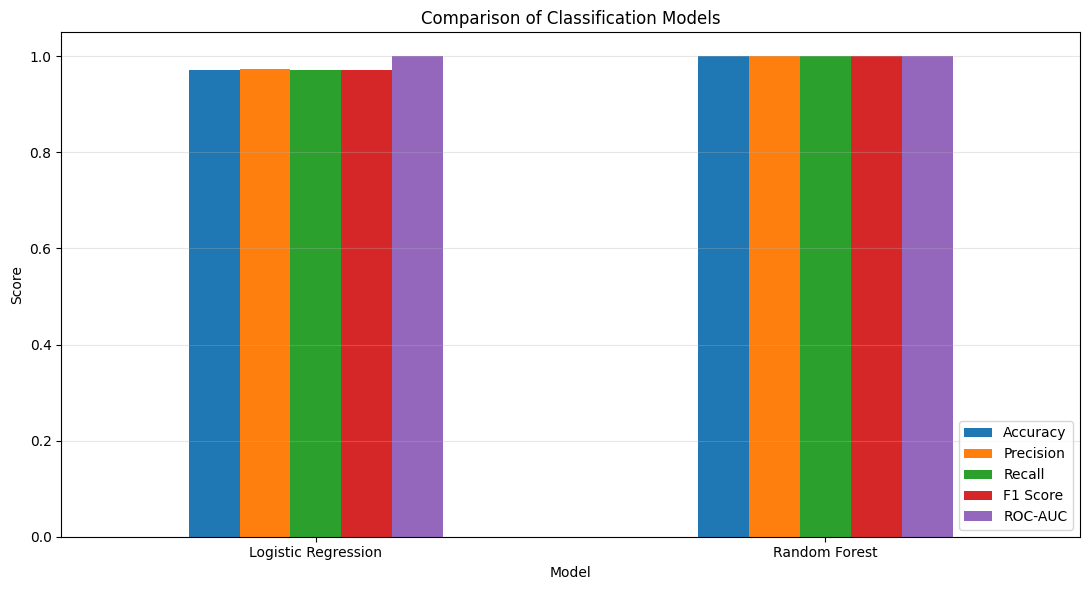

MODEL PERFORMANCE COMPARISON
----------------------------


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9722,0.9741,0.9722,0.972,1.0
1,Random Forest,1.0000,1.0000,1.0000,1.000,1.0


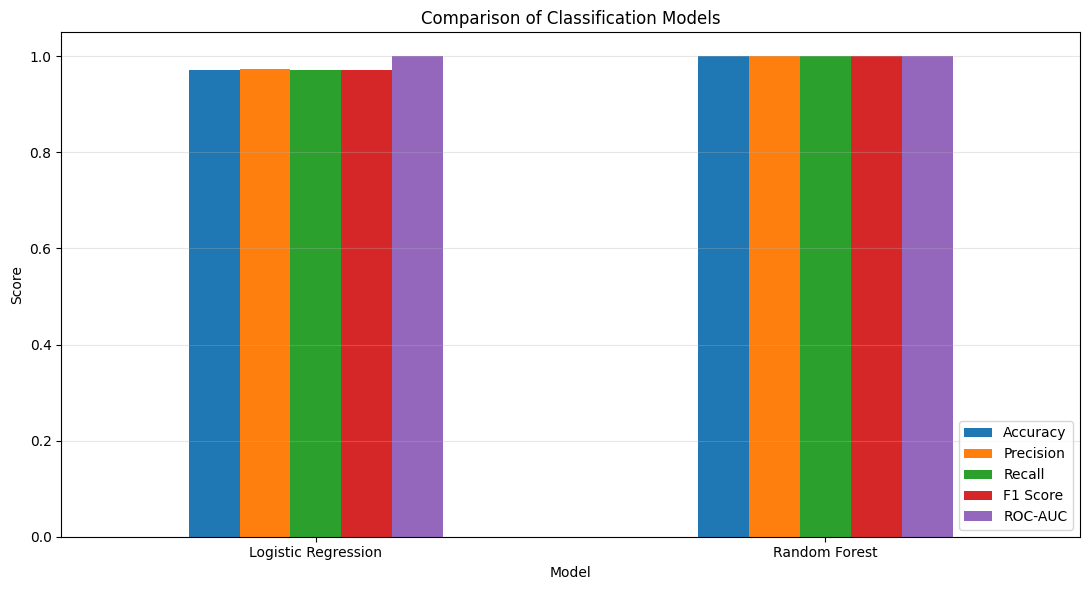

In [22]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, rf_accuracy],
    "Precision": [precision, rf_precision],
    "Recall": [recall, rf_recall],
    "F1 Score": [f1, rf_f1],
    "ROC-AUC": [roc_auc, rf_roc_auc]
})

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, rf_accuracy],
    "Precision": [precision, rf_precision],
    "Recall": [recall, rf_recall],
    "F1 Score": [f1, rf_f1],
    "ROC-AUC": [roc_auc, rf_roc_auc]
})

print("\n--------------------------")
print("MODEL PERFORMANCE COMPARISON")
print("\n--------------------------")

display(results.round(4))


# Visualize model comparison
results.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
print("MODEL PERFORMANCE COMPARISON")
print("----------------------------")

display(results.round(4))


# Visualize model comparison
results.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

IDENTIFY THE BETTER MODEL BY TEST ACCURACY

In [23]:
if accuracy > rf_accuracy:
    best_model = "Logistic Regression"
    best_score = accuracy
elif rf_accuracy > accuracy:
    best_model = "Random Forest"
    best_score = rf_accuracy
else:
    best_model = "Both models (tie)"
    best_score = accuracy

print("\nBest model by test accuracy:", best_model)
print(f"Test accuracy: {best_score:.4f}")


Best model by test accuracy: Random Forest
Test accuracy: 1.0000


FEATURE IMPORTANCE (RANDOM FOREST)


Top 10 important features:


,Importance
color_intensity,0.187580
flavanoids,0.159561
proline,0.146799
alcohol,0.117913
hue,0.101538
od280/od315_of_diluted_wines,0.096301
total_phenols,0.041514
magnesium,0.040131
malic_acid,0.033894
alcalinity_of_ash,0.025471


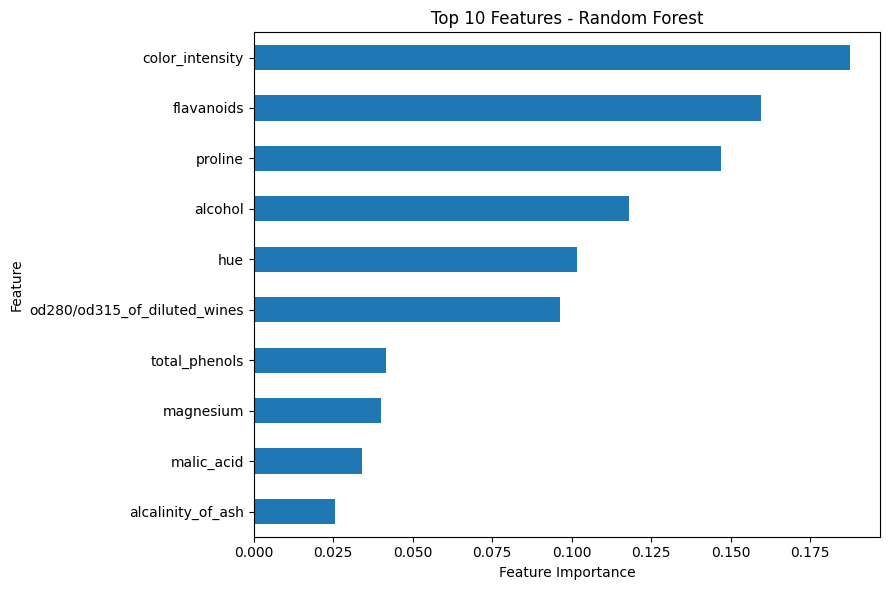

In [24]:
feature_importance = pd.Series(
    rf_pipeline.named_steps["classifier"].feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 10 important features:")
display(feature_importance.head(10).to_frame("Importance"))

plt.figure(figsize=(9, 6))

feature_importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

PREDICT THE CLASS OF A TEST SAMPLE

In [28]:
sample = X_test.iloc[[0]]

sample_prediction = logistic_pipeline.predict(sample)[0]
sample_probabilities = logistic_pipeline.predict_proba(sample)[0]

print("\n-------------------")
print("SAMPLE CLASSIFICATION")
print("---------------------")

print("Predicted wine class:",
      wine.target_names[sample_prediction])

print("Actual wine class:",
      wine.target_names[y_test.iloc[0]])

print("\nPredicted class probabilities:")

for class_name, probability in zip(
    wine.target_names, sample_probabilities
):
    print(f"{class_name}: {probability:.2%}")


-------------------
SAMPLE CLASSIFICATION
---------------------
Predicted wine class: class_0
Actual wine class: class_0

Predicted class probabilities:
class_0: 99.97%
class_1: 0.03%
class_2: 0.00%
